In [6]:
import pandas as pd

df = pd.read_csv('netflix_titles.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [8]:
# Eksik veri sayısı
print(df.isnull().sum())

# Gereksiz boşlukları temizle
df.columns = df.columns.str.strip()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


<Axes: title={'center': 'Film vs TV Show'}, xlabel='type'>

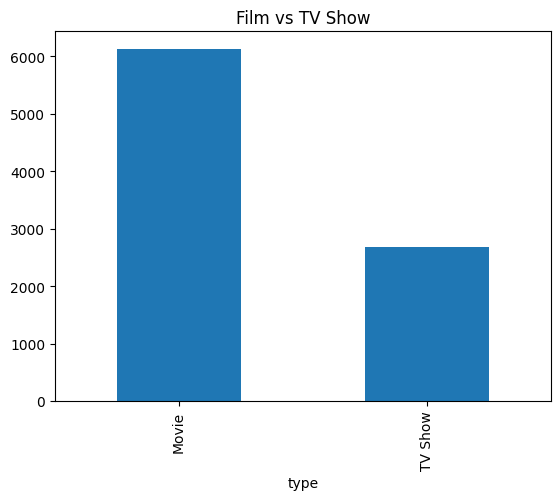

In [9]:
df['type'].value_counts().plot(kind='bar', title='Film vs TV Show')


<Axes: title={'center': 'Yıllara Göre Netflix İçerik Eklemesi'}, xlabel='year_added'>

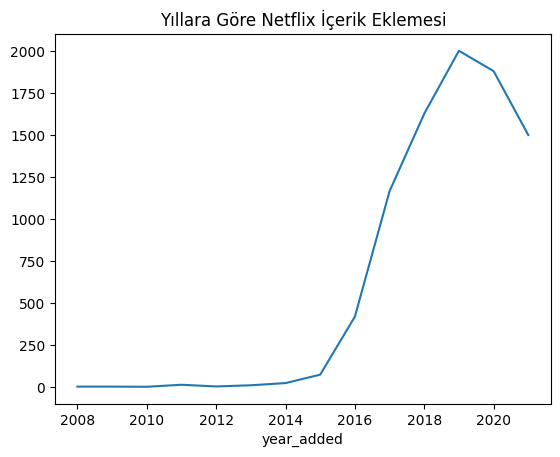

In [ ]:
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
df['year_added'] = df['date_added'].dt.year
df['year_added'].value_counts().sort_index().plot(kind='line', title='Yıllara Göre Netflix İçerik Eklemesi')


<Axes: title={'center': 'En Çok İçerik Üreten Ülkeler'}, ylabel='country'>

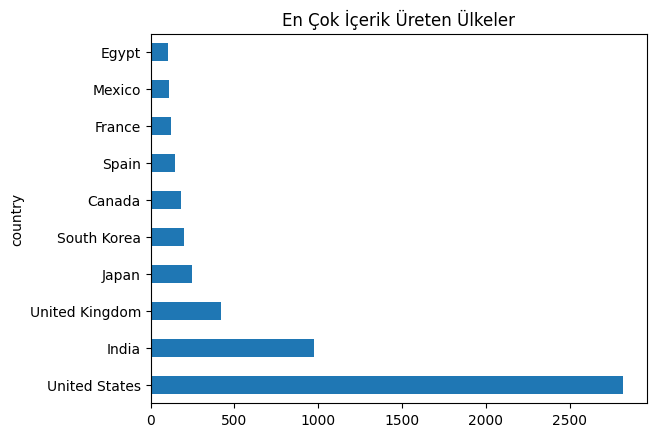

In [12]:
df['country'].value_counts().head(10).plot(kind='barh', title='En Çok İçerik Üreten Ülkeler')


In [20]:
directors = df[df['director'].notna()]
top_directors = directors['director'].value_counts().head(10)
print(top_directors)

director
Rajiv Chilaka             19
Raúl Campos, Jan Suter    18
Marcus Raboy              16
Suhas Kadav               16
Jay Karas                 14
Cathy Garcia-Molina       13
Martin Scorsese           12
Youssef Chahine           12
Jay Chapman               12
Steven Spielberg          11
Name: count, dtype: int64


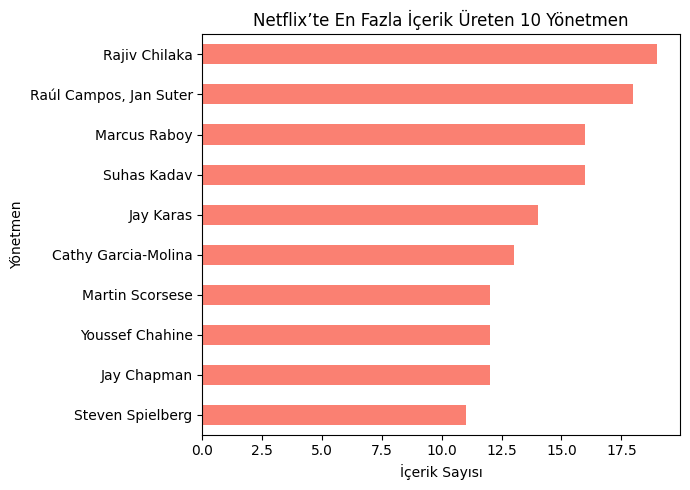

In [ ]:
import matplotlib.pyplot as plt

top_directors.plot(kind='barh', figsize=(7, 5), color='salmon')
plt.title('Netflix’te En Fazla İçerik Üreten 10 Yönetmen')
plt.xlabel('İçerik Sayısı')
plt.ylabel('Yönetmen')
plt.gca().invert_yaxis()  # En çok olanı üstte göstermek için
plt.tight_layout()
plt.show()


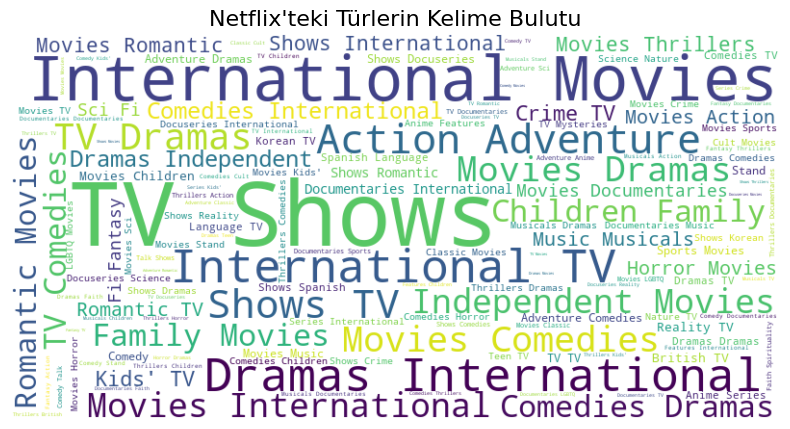

In [29]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Eksik olmayan tür verilerini al
genres = df['listed_in'].dropna()

# Tüm türleri ayır ve düz bir liste haline getir
genre_list = genres.str.split(', ')
all_genres = genre_list.explode()

# Türlerin sıklıklarını hesapla
genre_freq = all_genres.value_counts()

# Wordcloud için string hazırla
genre_string = ' '.join(all_genres)

# Kelime bulutu oluştur
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(genre_string)

# Görselleştir
plt.figure(figsize=(12, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Netflix'teki Türlerin Kelime Bulutu", fontsize=16)
plt.show()

In [31]:
def parse_duration(row):
    dur = row['duration']
    if pd.isna(dur):
        return None
    if 'Season' in dur:
        # Sezon sayısını çıkar
        return int(dur.split(' ')[0])
    elif 'min' in dur:
        # Dakika sayısını çıkar
        return int(dur.split(' ')[0])
    else:
        return None

# Yeni sütun oluştur: duration_num
df['duration_num'] = df.apply(parse_duration, axis=1)

# Film mi dizi mi olduğunu da gösterelim
df['type'] = df['type'].str.lower()  # küçük harfe çevir

# İstersen film/dizi ayrımı ile ayrı kolonlar da yapabilirsin:
df['duration_minutes'] = df.apply(lambda x: x['duration_num'] if 'film' in x['type'] else None, axis=1)
df['duration_seasons'] = df.apply(lambda x: x['duration_num'] if 'tv show' in x['type'] else None, axis=1)


for col in ['director', 'cast', 'country']:
    df[col].fillna('Unknown', inplace=True)


print(df[['director', 'cast', 'country']].isna().mean() * 100)  # % olarak boşluk oranı


director    0.0
cast        0.0
country     0.0
dtype: float64


C:\Users\rumeysagokce\AppData\Local\Temp\ipykernel_11064\1706487293.py:26: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna('Unknown', inplace=True)


In [32]:
#En uzun film?

# Önce sadece filmleri al
films = df[df['type'].str.lower() == 'movie']

# En uzun film (dakika cinsinden)
max_duration = films['duration_num'].max()

# Bu süreye sahip filmler
longest_films = films[films['duration_num'] == max_duration][['title', 'duration_num']]
print(longest_films)

                           title  duration_num
4253  Black Mirror: Bandersnatch         312.0


In [33]:
#En fazla sezonluk dizi?

# Sadece diziler
shows = df[df['type'].str.lower() == 'tv show']

# En fazla sezon
max_seasons = shows['duration_num'].max()

# Bu sezon sayısına sahip diziler
longest_shows = shows[shows['duration_num'] == max_seasons][['title', 'duration_num']]
print(longest_shows)


              title  duration_num
548  Grey's Anatomy          17.0


type
movie      1427
tv show    1148
Name: count, dtype: int64


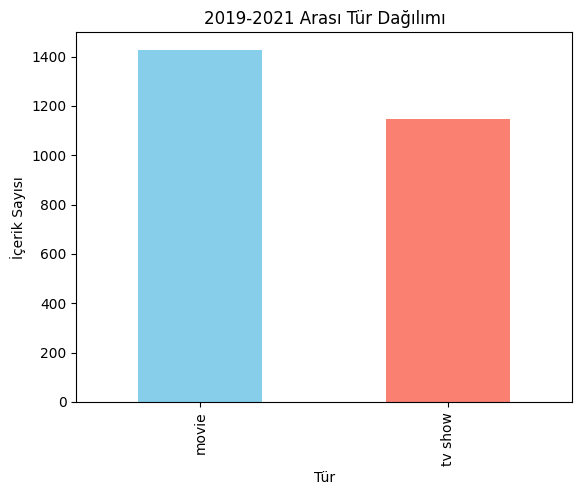

In [37]:
#Belirli yıllara göre içeriklerin tür dağılımı
#Burada 2019 ve 2021 yılları arası alındı.

# Tarih filtresi (release_year kullanabiliriz)
subset = df[(df['release_year'] >= 2019) & (df['release_year'] <= 2021)]

# Türlerin sayısı
type_counts = subset['type'].value_counts()
print(type_counts)

# Görselleştirme
type_counts.plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('2019-2021 Arası Tür Dağılımı')
plt.xlabel('Tür')
plt.ylabel('İçerik Sayısı')
plt.show()


In [ ]:
#Belirli bir ülkenin içerik ortalaması ne?
#Burada US

country = "United States"

# Ülke bazında filtrele (country sütununda ülke adı geçiyor mu diye kontrol et)
country_contents = df[df['country'].str.contains(country, na=False)]

# Ortalama süre (dakika ve sezon)
avg_duration = country_contents['duration_num'].mean()

print(f"{country} için ortalama içerik süresi: {avg_duration:.2f}")


United States için ortalama içerik süresi: 70.49
